# AgroSmart Puno · UNIDAD 1 — Arquitectura Big Data y ETL batch distribuido (S1 → S5)
**Estudiante:** Jose Armando Mamani Poccohuanca · **Equipo Proyecto Sello:** Jose Armando Mamani Poccohuanca y Mijael Yurins Coaquira Justo
**Pregunta central del proyecto:** ¿cómo anticipar a corto plazo las condiciones meteorológicas de riesgo agrícola del altiplano de Puno (estrés hídrico del suelo y heladas) a partir de datos de Open-Meteo?
**Dimensión de José:** *humedad del suelo* (¿qué humedad del suelo se espera en Puno 1, 2 y 3 h después?).
**DimensiónU1 (indicador batch, sin tiempo real):** humedad histórica limpia y humedad esperada por un modelo de regresión (foto fija).
**Alcance:** *solo humedad* — humedad volumétrica del suelo (0–1 cm, %) como variable a predecir y humedad relativa del aire (2 m, %) como variable complementaria.

Este cuaderno reproduce, **sesión por sesión**, lo que pide el docente en la Unidad 1 ([lambda26](https://262bigdata.github.io/lambda26/)) pero aplicado al caso AgroSmart:

| Sesión | Tema | Sección de este cuaderno |
|---|---|---|
| S1 | Arquitectura Lambda/Kappa, batch vs. streaming | Sección 1 |
| S2 | Fundamentos PySpark: transformaciones, lazy evaluation, agrupaciones, RDD | Sección 2 |
| S3 | Calidad de datos (esquema, nulos, duplicados) y Parquet particionado | Sección 3 |
| S4 | ML distribuido con MLlib (regresión, CRISP-DM) | Sección 4 |
| S5 | Evaluación de la Unidad I: pipeline batch completo | Sección 5 |

**Datos:** `data/AgroSmart_Humedad_U1.xlsx` (Excel de negocio con 3 hojas) y sus copias CSV. La base es **real** (Open-Meteo modelado, Puno) con **fallas inyectadas a propósito** (código de error −999, nulos, duplicados) para practicar calidad de datos; la hoja `suelo_1_3cm_sim` es **simulada**. Nada de esto son sensores físicos.

> **Cómo ejecutar:** Docker → `pyspark/compose.yml` → Jupyter `http://localhost:4489/lab` (token en `.env`). Abre este archivo desde `U1_Batch_Humedad/` y ejecuta **de arriba hacia abajo**.

---
# SECCIÓN 1 · S1 — Arquitectura Big Data: Lambda y Kappa, batch vs. streaming
**Producto de sesión:** arquitectura seleccionada y justificada + entorno verificado (Jupyter + Spark + Spark UI).

## 1.1 Verificar el entorno `lambda26` (Docker + Jupyter + Spark)

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, StringType, DoubleType

RAIZ = Path('/home/jovyan/work/U1_Batch_Humedad')
DATOS = RAIZ / 'data'
ARTIFACTS = RAIZ / 'artifacts'
for p in (DATOS, ARTIFACTS): p.mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder
    .appName('AgroSmart-U1-Batch').master('local[*]')
    .config('spark.ui.port', '4040')
    .config('spark.sql.shuffle.partitions', '8')
    .config('spark.driver.memory', '2g')
    .config('spark.sql.session.timeZone', 'UTC')
    .getOrCreate())
spark.sparkContext.setLogLevel('WARN')
print('Spark', spark.version, '| master:', spark.sparkContext.master)
print('Spark UI en tu navegador: http://localhost:4041  (puerto 4040 del contenedor)')
print('Ejecución:', datetime.now(timezone.utc).isoformat())
print('Archivos de datos:', sorted(p.name for p in DATOS.iterdir()))

Spark 3.5.0 | master: local[*]
Spark UI en tu navegador: http://localhost:4041  (puerto 4040 del contenedor)
Ejecución: 2026-11-20T05:47:21.334232+00:00
Archivos de datos: ['AgroSmart_Humedad_U1.xlsx', 'aire_2m.csv', 'suelo_0_1cm.csv', 'suelo_1_3cm_sim.csv']


## 1.2 Ecosistema Big Data y las 5V aplicadas a AgroSmart

| V | En AgroSmart (solo humedad) |
|---|---|
| **Volumen** | 1 lectura/hora × 2 variables; crece al sumar sensores/parcelas. Hoy es pequeño: es un laboratorio, el *diseño* es lo que escala. |
| **Variedad** | Excel (fuente de negocio), CSV, JSON (API), eventos Kafka, Parquet. |
| **Velocidad** | Datos horarios de la API; el pipeline en streaming los procesa conforme llegan (Unidad 2). |
| **Veracidad** | Valores *modelados* por Open-Meteo, no sondas; hay códigos de error (−999), nulos y duplicados. |
| **Valor** | Anticipar la humedad del suelo a +1, +2 y +3 horas para apoyar decisiones de riego (alertas didácticas, no recomendación agronómica validada). |

Flujo base de una solución Big Data: `Fuente → Ingesta → Almacenamiento → Procesamiento → Visualización/consumo`.

## 1.3 Batch vs. streaming (clasificación del caso)

In [2]:
clasificacion = pd.DataFrame([
  ['Entrenar modelos con meses de humedad histórica', 'BATCH', 'Datos acumulados, se procesa periódicamente (Unidad 1).'],
  ['Limpiar, deduplicar y guardar histórico en Parquet', 'BATCH', 'ETL sobre archivos; resultado reutilizable por BI/ML.'],
  ['Recibir cada lectura horaria de la API', 'STREAMING', 'Evento nuevo cada hora; se procesa al llegar (Kafka).'],
  ['Predecir +1/+2/+3 h al llegar cada lectura', 'STREAMING', 'Inferencia en tiempo real con el modelo entrenado en batch.'],
  ['Mostrar humedad observada vs. predicha en Grafana', 'SERVING', 'Capa de consulta que combina histórico y tiempo real.'],
], columns=['Tarea del caso AgroSmart', 'Tipo', 'Justificación'])
display(clasificacion)

,Tarea del caso AgroSmart,Tipo,Justificación
0,Entrenar modelos con meses de humedad histórica,BATCH,"Datos acumulados, se procesa periódicamente (U..."
1,"Limpiar, deduplicar y guardar histórico en Par...",BATCH,ETL sobre archivos; resultado reutilizable por...
2,Recibir cada lectura horaria de la API,STREAMING,Evento nuevo cada hora; se procesa al llegar (...
3,Predecir +1/+2/+3 h al llegar cada lectura,STREAMING,Inferencia en tiempo real con el modelo entren...
4,Mostrar humedad observada vs. predicha en Grafana,SERVING,Capa de consulta que combina histórico y tiemp...


## 1.4 Regla de decisión y arquitectura seleccionada

- *Histórico + tiempo real* → **Lambda**. *Todo son eventos en tiempo real* → **Kappa**.
- AgroSmart necesita **ambos**: entrenar con histórico (batch) **y** predecir con cada lectura nueva (streaming) → **Arquitectura LAMBDA**.

```
                     ┌──────────────► BATCH LAYER  (Unidad 1: PySpark + Parquet + MLlib) ──► modelo entrenado ─┐
Open-Meteo / Excel ──┤                                                                                         ▼
                     └─► Kafka ───► SPEED LAYER (Unidad 2: Spark Structured Streaming + inferencia) ──► SERVING LAYER
                                                                                                    (PostgreSQL + Grafana)
```
Lo único que cruza del batch al tiempo real es **el modelo entrenado** (misma idea que Uber/`lambda26`). **Riesgo de deriva (drift):** dos códigos (batch y streaming) pueden calcular distinto; se mitiga usando *las mismas variables* y el *mismo `Pipeline` guardado* en ambos.

## 1.5 Ficha de propuesta arquitectónica (plantilla S1, 3.7)

In [3]:
ficha = pd.DataFrame({'Campo': ['Caso analizado','Tipo de procesamiento','Arquitectura seleccionada','Diagrama','Tecnologías propuestas','Supuestos','Riesgos y limitaciones'],
 'AgroSmart Puno (humedad)': [
  'Monitoreo y predicción de humedad del suelo (0–1 cm) en Puno, con humedad del aire como variable complementaria; 1 lectura/hora desde Open-Meteo.',
  'AMBOS: batch (entrenamiento histórico) + streaming (inferencia por evento).',
  'LAMBDA (batch + speed + serving) porque se necesita histórico y tiempo real.',
  'Fuente(API/Excel) → Kafka → Spark (batch+streaming) → Parquet/PostgreSQL → Grafana',
  'Ingesta: Kafka · Procesamiento: PySpark/MLlib/Structured Streaming · Almacenamiento: Parquet + PostgreSQL · Visualización: Grafana · Observabilidad: Prometheus',
  'Valores modelados por Open-Meteo representan la humedad del terreno; la hora es suficiente señal temporal para un modelo base.',
  'No hay sondas físicas; la API puede repetir valores; un solo nodo (no HA); umbral de 20 % es solo didáctico; deriva batch/streaming.']})
with pd.option_context('display.max_colwidth', None): display(ficha)

,Campo,AgroSmart Puno (humedad)
0,Caso analizado,"Monitoreo y predicción de humedad del suelo (0–1 cm) en Puno, con humedad del aire como variable complementaria; 1 lectura/hora desde Open-Meteo."
1,Tipo de procesamiento,AMBOS: batch (entrenamiento histórico) + streaming (inferencia por evento).
2,Arquitectura seleccionada,LAMBDA (batch + speed + serving) porque se necesita histórico y tiempo real.
3,Diagrama,Fuente(API/Excel) → Kafka → Spark (batch+streaming) → Parquet/PostgreSQL → Grafana
4,Tecnologías propuestas,Ingesta: Kafka · Procesamiento: PySpark/MLlib/Structured Streaming · Almacenamiento: Parquet + PostgreSQL · Visualización: Grafana · Observabilidad: Prometheus
5,Supuestos,Valores modelados por Open-Meteo representan la humedad del terreno; la hora es suficiente señal temporal para un modelo base.
6,Riesgos y limitaciones,No hay sondas físicas; la API puede repetir valores; un solo nodo (no HA); umbral de 20 % es solo didáctico; deriva batch/streaming.


### 1.6 Reflexión S1 (5–8 líneas)
*¿Qué arquitectura usarías para un sistema de sensores IoT y por qué?* → **Lambda si además del tiempo real se necesita reentrenar con histórico** (caso AgroSmart); **Kappa** si todo se reduce a eventos y el reprocesamiento puede hacerse reproduciendo el tópico de Kafka. Elegí Lambda porque el modelo se entrena sobre meses de datos (batch) y se aplica a cada lectura nueva (speed), a costa de mantener dos capas.

---
# SECCIÓN 2 · S2 — Fundamentos PySpark: transformaciones, lazy evaluation, agrupaciones y RDD
**Producto:** transformaciones documentadas, `explain()` interpretado, agrupaciones y conteo RDD.

## 2.1 El Excel como fuente de negocio → CSV para Spark
Spark lee CSV/Parquet; el Excel es la fuente original. Verificamos que el Excel y los CSV contengan lo mismo.

In [4]:
XLSX = DATOS / 'AgroSmart_Humedad_U1.xlsx'
try:
    hojas = pd.read_excel(XLSX, sheet_name=None)          # requiere openpyxl (incluido en el Dockerfile)
    print({k: v.shape for k, v in hojas.items()})
    display(hojas['diccionario'])
    assert len(hojas['suelo_0_1cm']) == len(pd.read_csv(DATOS/'suelo_0_1cm.csv'))
    print('Excel y CSV coinciden en filas.')
except ImportError:
    print('openpyxl no está instalado: se usan solo los CSV (reconstruye la imagen con --build).')

{'suelo_0_1cm': (1439, 2), 'aire_2m': (1469, 2), 'suelo_1_3cm_sim': (1439, 2), 'diccionario': (6, 4)}


,hoja,columna,unidad,descripcion
0,suelo_0_1cm,fecha_hora,"UTC, cada hora",Clave de integración
1,suelo_0_1cm,humedad_suelo_pct,% volumétrico,OBJETIVO. -999 = código de error de sensor; va...
2,aire_2m,fecha_hora,"UTC, cada hora",Clave; puede venir DUPLICADA
3,aire_2m,humedad_aire_pct,% relativa,Open-Meteo (modelado) con nulos y duplicados i...
4,suelo_1_3cm_sim,fecha_hora,"UTC, cada hora",Clave de integración
5,suelo_1_3cm_sim,humedad_suelo_1_3cm_pct,% volumétrico,SIMULADA a partir de la 0-1 cm; no es medición


Excel y CSV coinciden en filas.


## 2.2 Cargar con esquema explícito (control de tipos)
`inferSchema` puede adivinar mal; declaramos el esquema nosotros.

In [5]:
schema_suelo = StructType([StructField('fecha_hora', StringType(), True), StructField('humedad_suelo_pct', DoubleType(), True)])
schema_aire  = StructType([StructField('fecha_hora', StringType(), True), StructField('humedad_aire_pct', DoubleType(), True)])
schema_s13   = StructType([StructField('fecha_hora', StringType(), True), StructField('humedad_suelo_1_3cm_pct', DoubleType(), True)])

df_suelo = spark.read.csv(str(DATOS/'suelo_0_1cm.csv'), header=True, schema=schema_suelo)
df_aire  = spark.read.csv(str(DATOS/'aire_2m.csv'),     header=True, schema=schema_aire)
df_s13   = spark.read.csv(str(DATOS/'suelo_1_3cm_sim.csv'), header=True, schema=schema_s13)

for nombre, d in [('suelo 0-1 cm', df_suelo), ('aire 2 m', df_aire), ('suelo 1-3 cm (sim)', df_s13)]:
    print(f'== {nombre}: {d.count():,} filas')
    d.printSchema()
df_suelo.show(5, truncate=False)
df_suelo.describe('humedad_suelo_pct').show()

== suelo 0-1 cm: 1,439 filas
root
 |-- fecha_hora: string (nullable = true)
 |-- humedad_suelo_pct: double (nullable = true)

== aire 2 m: 1,469 filas
root
 |-- fecha_hora: string (nullable = true)
 |-- humedad_aire_pct: double (nullable = true)

== suelo 1-3 cm (sim): 1,439 filas
root
 |-- fecha_hora: string (nullable = true)
 |-- humedad_suelo_1_3cm_pct: double (nullable = true)

+-------------------+-----------------+
|fecha_hora         |humedad_suelo_pct|
+-------------------+-----------------+
|2026-09-07 20:00:00|6.6              |
|2026-09-07 21:00:00|6.6              |
|2026-09-07 22:00:00|6.6              |
|2026-09-07 23:00:00|15.5             |
|2026-09-08 00:00:00|6.0              |
+-------------------+-----------------+
only showing top 5 rows

+-------+-------------------+
|summary|  humedad_suelo_pct|
+-------+-------------------+
|  count|               1424|
|   mean|-3.5962780898876234|
| stddev| 133.22281799378482|
|    min|             -999.0|
|    max|           

## 2.3 Transformaciones vs. acciones y evaluación perezosa
Las **transformaciones** (`select`, `filter`, `withColumn`, `groupBy`) solo construyen un *plan*; la **acción** (`show`, `count`, `collect`, `write`) lo ejecuta. Lo demostramos midiendo tiempos.

In [6]:
import time
t0 = time.perf_counter()
plan = (df_suelo.select('fecha_hora', 'humedad_suelo_pct')
        .filter(F.col('humedad_suelo_pct') > 20)          # transformación
        .withColumn('mitad', F.col('humedad_suelo_pct') / 2))   # transformación
t_plan = time.perf_counter() - t0
t0 = time.perf_counter(); n = plan.count(); t_accion = time.perf_counter() - t0   # ACCIÓN
print(f'Construir el plan (transformaciones): {t_plan*1000:.1f} ms  → no leyó ningún dato')
print(f'Ejecutar la acción count():           {t_accion*1000:.1f} ms  → {n} filas con humedad > 20 %')

Construir el plan (transformaciones): 99.5 ms  → no leyó ningún dato
Ejecutar la acción count():           453.0 ms  → 186 filas con humedad > 20 %


## 2.4 Plan de ejecución con `explain(True)` (Catalyst)
Se lee **de abajo hacia arriba**. Busca que el `Filter` quede *antes* del `Project` en el *Optimized Logical Plan* (**predicate pushdown**) y los `PushedFilters` / `ReadSchema` del plan físico.

In [7]:
plan.explain(True)

== Parsed Logical Plan ==
'Project [fecha_hora#0, humedad_suelo_pct#1, ('humedad_suelo_pct / 2) AS mitad#140]
+- Filter (humedad_suelo_pct#1 > cast(20 as double))
   +- Project [fecha_hora#0, humedad_suelo_pct#1]
      +- Relation [fecha_hora#0,humedad_suelo_pct#1] csv

== Analyzed Logical Plan ==
fecha_hora: string, humedad_suelo_pct: double, mitad: double
Project [fecha_hora#0, humedad_suelo_pct#1, (humedad_suelo_pct#1 / cast(2 as double)) AS mitad#140]
+- Filter (humedad_suelo_pct#1 > cast(20 as double))
   +- Project [fecha_hora#0, humedad_suelo_pct#1]
      +- Relation [fecha_hora#0,humedad_suelo_pct#1] csv

== Optimized Logical Plan ==
Project [fecha_hora#0, humedad_suelo_pct#1, (humedad_suelo_pct#1 / 2.0) AS mitad#140]
+- Filter (isnotnull(humedad_suelo_pct#1) AND (humedad_suelo_pct#1 > 20.0))
   +- Relation [fecha_hora#0,humedad_suelo_pct#1] csv

== Physical Plan ==
*(1) Project [fecha_hora#0, humedad_suelo_pct#1, (humedad_suelo_pct#1 / 2.0) AS mitad#140]
+- *(1) Filter (isnotn

**Cómo interpretarlo:** *Parsed* = tu código; *Analyzed* = nombres y tipos resueltos; *Optimized* = Catalyst reordena (filtra antes de proyectar y agrega `isnotnull(humedad_suelo_pct)` por su cuenta); *Physical* = receta real (`FileScan csv`, `PushedFilters`, solo se leen las columnas usadas). Mismo resultado, menos datos procesados.

## 2.5 Funciones de columna con `withColumn()` (cast, to_timestamp, when, lit, current_date)

In [8]:
df_s = (df_suelo
    .withColumn('ts', F.to_timestamp('fecha_hora', 'yyyy-MM-dd HH:mm:ss'))                 # texto → timestamp
    .withColumn('hora', F.hour('ts'))
    .withColumn('categoria_suelo',                                                          # when / otherwise
        F.when(F.col('humedad_suelo_pct') == -999, 'ERROR_SENSOR')
         .when(F.col('humedad_suelo_pct').isNull(), 'SIN_DATO')
         .when(F.col('humedad_suelo_pct') < 10, 'SECO')
         .when(F.col('humedad_suelo_pct') <= 20, 'MEDIO')
         .otherwise('HUMEDO'))
    .withColumn('fuente', F.lit('Open-Meteo modelado'))                                     # constante
    .withColumn('fecha_procesado', F.current_date()))                                       # calculada por Spark
df_s.select('fecha_hora','humedad_suelo_pct','categoria_suelo','hora','fuente','fecha_procesado').show(8, truncate=False)

+-------------------+-----------------+---------------+----+-------------------+---------------+
|fecha_hora         |humedad_suelo_pct|categoria_suelo|hora|fuente             |fecha_procesado|
+-------------------+-----------------+---------------+----+-------------------+---------------+
|2026-09-07 20:00:00|6.6              |SECO           |20  |Open-Meteo modelado|2026-11-20     |
|2026-09-07 21:00:00|6.6              |SECO           |21  |Open-Meteo modelado|2026-11-20     |
|2026-09-07 22:00:00|6.6              |SECO           |22  |Open-Meteo modelado|2026-11-20     |
|2026-09-07 23:00:00|15.5             |MEDIO          |23  |Open-Meteo modelado|2026-11-20     |
|2026-09-08 00:00:00|6.0              |SECO           |0   |Open-Meteo modelado|2026-11-20     |
|2026-09-08 01:00:00|6.1              |SECO           |1   |Open-Meteo modelado|2026-11-20     |
|2026-09-08 02:00:00|6.2              |SECO           |2   |Open-Meteo modelado|2026-11-20     |
|2026-09-08 03:00:00|6.3      

## 2.6 Agrupaciones y agregaciones
`groupBy()` define grupos; `.agg()` calcula un valor por grupo (colapsa filas). Usamos solo lecturas válidas.

+---------------+--------+-----+------+------+
|categoria_suelo|lecturas|media|minimo|maximo|
+---------------+--------+-----+------+------+
|          MEDIO|    1010|13.17|  10.0|  20.0|
|           SECO|     203| 8.54|   6.0|   9.9|
|         HUMEDO|     186|25.89|  20.1|  37.9|
+---------------+--------+-----+------+------+



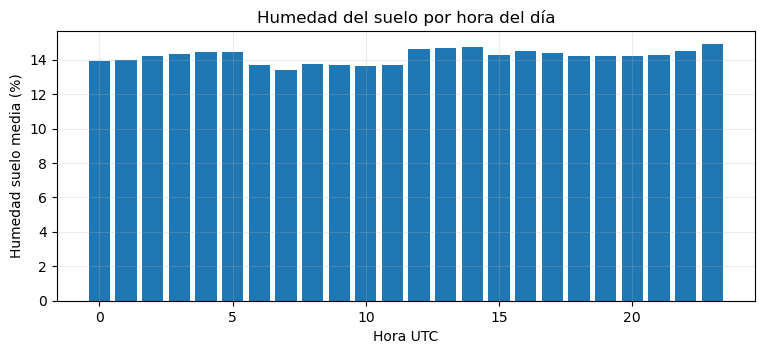

In [9]:
validos = df_s.filter(~F.col('categoria_suelo').isin('ERROR_SENSOR','SIN_DATO'))
por_cat = (validos.groupBy('categoria_suelo')
    .agg(F.count('*').alias('lecturas'), F.round(F.avg('humedad_suelo_pct'),2).alias('media'),
         F.min('humedad_suelo_pct').alias('minimo'), F.max('humedad_suelo_pct').alias('maximo'))
    .orderBy('lecturas', ascending=False))
por_cat.show()

por_hora = (validos.groupBy('hora').agg(F.round(F.avg('humedad_suelo_pct'),2).alias('suelo_medio'),
            F.countDistinct('fecha_hora').alias('lecturas')).orderBy('hora'))
ph = por_hora.toPandas()
plt.figure(figsize=(9,3.5)); plt.bar(ph.hora, ph.suelo_medio); plt.xlabel('Hora UTC'); plt.ylabel('Humedad suelo media (%)')
plt.title('Humedad del suelo por hora del día'); plt.grid(alpha=.25); plt.show()

## 2.7 Función ventana (`Window`): agregar **sin perder filas**
`groupBy().agg()` colapsa; una ventana conserva cada fila y le agrega el resumen. Aquí: media móvil de 3 horas (la fila actual + 2 anteriores) y el máximo diario.

In [10]:
v_movil = Window.orderBy('ts').rowsBetween(-2, 0)
v_dia   = Window.partitionBy(F.to_date('ts'))
df_vent = (validos.withColumn('media_movil_3h', F.round(F.avg('humedad_suelo_pct').over(v_movil), 2))
                  .withColumn('max_del_dia', F.max('humedad_suelo_pct').over(v_dia)))
df_vent.select('fecha_hora','humedad_suelo_pct','media_movil_3h','max_del_dia').orderBy('ts').show(8, truncate=False)

+-------------------+-----------------+--------------+-----------+
|fecha_hora         |humedad_suelo_pct|media_movil_3h|max_del_dia|
+-------------------+-----------------+--------------+-----------+
|2026-09-07 20:00:00|6.6              |6.6           |15.5       |
|2026-09-07 21:00:00|6.6              |6.6           |15.5       |
|2026-09-07 22:00:00|6.6              |6.6           |15.5       |
|2026-09-07 23:00:00|15.5             |9.57          |15.5       |
|2026-09-08 00:00:00|6.0              |9.37          |12.6       |
|2026-09-08 01:00:00|6.1              |9.2           |12.6       |
|2026-09-08 02:00:00|6.2              |6.1           |12.6       |
|2026-09-08 03:00:00|6.3              |6.2           |12.6       |
+-------------------+-----------------+--------------+-----------+
only showing top 8 rows



## 2.8 RDD: el modelo debajo de los DataFrames (map / reduceByKey)
Mismo patrón MapReduce del *conteo de palabras* (S2), aplicado a categorías: contamos lecturas por categoría de humedad con `map` + `reduceByKey` (shuffle = agrupar claves iguales).

In [11]:
from operator import add
rdd = df_s.select('categoria_suelo').rdd.map(lambda r: r.categoria_suelo)       # DataFrame → RDD
pares = rdd.map(lambda c: (c, 1))                                               # Mapping
conteo = pares.reduceByKey(add)                                                 # Shuffling + Reducing
print(sorted(conteo.collect(), key=lambda x: -x[1]))
# Verificación cruzada con el DataFrame:
print(sorted([(r.categoria_suelo, r['count']) for r in df_s.groupBy('categoria_suelo').count().collect()], key=lambda x: -x[1]))
# Un RDD no pasa por Catalyst: para datos tabulares conviene DataFrame; RDD para lógica funcional (texto libre).

[('MEDIO', 1010), ('SECO', 203), ('HUMEDO', 186), ('ERROR_SENSOR', 25), ('SIN_DATO', 15)]
[('MEDIO', 1010), ('SECO', 203), ('HUMEDO', 186), ('ERROR_SENSOR', 25), ('SIN_DATO', 15)]


## 2.9 `cache()` cuando un DataFrame se reutiliza en varias acciones

In [12]:
cache_df = validos.cache()
t0=time.perf_counter(); n1 = cache_df.count(); t1=time.perf_counter()-t0           # calcula y guarda
t0=time.perf_counter(); n2 = cache_df.count(); t2=time.perf_counter()-t0           # usa memoria
print(f'1.ª acción: {t1*1000:.0f} ms · 2.ª acción (desde caché): {t2*1000:.0f} ms · filas: {n1}=={n2}')
cache_df.unpersist();

1.ª acción: 435 ms · 2.ª acción (desde caché): 165 ms · filas: 1399==1399


### 2.10 Hallazgos S2 (documenta con tus palabras)
- Distinguí transformación vs. acción y lo medí (2.3).
- `explain()` mostró *predicate pushdown* y *column pruning* (2.4).
- **Advertencia de dominio:** la humedad del suelo es **% volumétrico modelado**, no mm de agua ni medición de sonda.
- Una ventana (2.7) conserva detalle; `groupBy` (2.6) lo colapsa. El RDD (2.8) no se optimiza con Catalyst.

---
# SECCIÓN 3 · S3 — Procesamiento y calidad de datos: filtrado, duplicados, nulos y particionamiento
**Producto:** datos validados, integrados y guardados como **Parquet particionado** (capa Gold) listos para ML/BI.
Las tres capas: **Bronze** = CSV/Excel tal cual · **Silver** = integrado y limpio · **Gold** = Parquet particionado por mes.

## 3.1 Control #1 — Validación de esquema (columnas obligatorias)

In [13]:
requeridas = {'suelo_0_1cm': {'fecha_hora','humedad_suelo_pct'}, 'aire_2m': {'fecha_hora','humedad_aire_pct'},
              'suelo_1_3cm_sim': {'fecha_hora','humedad_suelo_1_3cm_pct'}}
for nombre, d in [('suelo_0_1cm', df_suelo), ('aire_2m', df_aire), ('suelo_1_3cm_sim', df_s13)]:
    faltan = requeridas[nombre] - set(d.columns)
    if faltan: raise ValueError(f'{nombre}: faltan columnas {sorted(faltan)}')
print('Esquema validado: todas las columnas obligatorias están presentes.')
conteos_bronze = {'suelo': df_suelo.count(), 'aire': df_aire.count(), 's13': df_s13.count()}
print('Filas Bronze:', conteos_bronze)

Esquema validado: todas las columnas obligatorias están presentes.
Filas Bronze: {'suelo': 1439, 'aire': 1469, 's13': 1439}


## 3.2 Control #2 — Nulos **y códigos de error** (no son lo mismo)
`-999` es un *valor válido para Spark* (un `double`): `isNull()` **no** lo detecta. Hay que contarlo por separado.

In [14]:
def nulos(d):
    return d.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in d.columns]).collect()[0].asDict()
tot_suelo = df_suelo.count()
n_suelo = nulos(df_suelo); n_aire = nulos(df_aire)
n_err = df_suelo.filter(F.col('humedad_suelo_pct') == -999).count()
print('Nulos suelo:', n_suelo); print('Nulos aire :', n_aire)
print(f'Códigos de error -999 en suelo: {n_err} ({n_err/tot_suelo*100:.1f} %)')
print('Cadenas vacías en fecha_hora:', df_suelo.filter(F.trim('fecha_hora') == '').count())
# Verificación cruzada con pandas (independiente de Spark)
pa = pd.read_csv(DATOS/'suelo_0_1cm.csv'); pb = pd.read_csv(DATOS/'aire_2m.csv')
assert n_err == int((pa.humedad_suelo_pct == -999).sum()) and n_suelo['humedad_suelo_pct'] == int(pa.humedad_suelo_pct.isna().sum())
print('OK: conteos de Spark = conteos de pandas.')

Nulos suelo: {'fecha_hora': 0, 'humedad_suelo_pct': 15}
Nulos aire : {'fecha_hora': 0, 'humedad_aire_pct': 20}
Códigos de error -999 en suelo: 25 (1.7 %)
Cadenas vacías en fecha_hora: 0
OK: conteos de Spark = conteos de pandas.


## 3.3 Control #3 — Duplicados
Un `join` con clave duplicada **multiplica filas sin error**. Primero **diagnosticamos** (`groupBy().count()>1`), luego **tratamos** con `Window + row_number()`, conservando la fila con **menos nulos** (criterio determinista).

In [15]:
dups = df_aire.groupBy('fecha_hora').count().filter('count > 1')
print('Marcas de tiempo duplicadas en aire:', dups.count()); dups.show(5, truncate=False)

df_aire_n = df_aire.withColumn('n_nulos', F.when(F.col('humedad_aire_pct').isNull(), 1).otherwise(0))
w = Window.partitionBy('fecha_hora').orderBy(F.col('n_nulos').asc(), F.col('humedad_aire_pct').desc_nulls_last())
df_aire_u = (df_aire_n.withColumn('rn', F.row_number().over(w)).filter('rn = 1').drop('rn','n_nulos'))
print(f'Aire: {df_aire.count()} filas → {df_aire_u.count()} sin duplicar')
assert df_aire_u.count() == df_aire_u.dropDuplicates(['fecha_hora']).count() == pb.fecha_hora.nunique()
# Contraste: dropDuplicates() elige UNA cualquiera; Window te deja elegir CUÁL.

Marcas de tiempo duplicadas en aire: 30
+-------------------+-----+
|fecha_hora         |count|
+-------------------+-----+
|2026-09-29 20:00:00|2    |
|2026-10-04 10:00:00|2    |
|2026-10-20 21:00:00|2    |
|2026-10-30 02:00:00|2    |
|2026-11-02 16:00:00|2    |
+-------------------+-----+
only showing top 5 rows

Aire: 1469 filas → 1439 sin duplicar


## 3.4 Integración (Silver): limpiar + unir por `fecha_hora`
Reglas de calidad aplicadas (cada una documentada):
1. `-999` → **se descarta la fila** (no es humedad; rellenar con 0 inventaría un dato falso).
2. Nulo en la **variable objetivo** (suelo 0-1) → se descarta (sin objetivo no se puede entrenar).
3. Nulo en **aire** (variable complementaria) → se descarta para el modelo (son pocos; no se inventa un promedio).
4. Clave `fecha_hora` → `timestamp` UTC; `left join` desde la fuente principal (suelo).

In [16]:
suelo_ok = (df_suelo.filter(F.col('humedad_suelo_pct') != -999).na.drop(subset=['humedad_suelo_pct'])
            .withColumn('ts', F.to_timestamp('fecha_hora', 'yyyy-MM-dd HH:mm:ss')))
aire_u = df_aire_u.select('fecha_hora', 'humedad_aire_pct')
s13 = df_s13.select('fecha_hora', 'humedad_suelo_1_3cm_pct')

silver = (suelo_ok.join(aire_u, 'fecha_hora', 'left').join(s13, 'fecha_hora', 'left')
          .na.drop(subset=['humedad_aire_pct', 'humedad_suelo_1_3cm_pct'])
          .select('ts', 'humedad_suelo_pct', 'humedad_aire_pct', 'humedad_suelo_1_3cm_pct')
          .orderBy('ts'))
silver = silver.cache()
n_silver = silver.count()
print(f'Silver: {n_silver:,} filas  (Bronze suelo {tot_suelo:,} → descartadas {tot_suelo - n_silver:,} por calidad)')
assert n_silver == silver.dropDuplicates(['ts']).count(), 'hay ts repetido'
assert silver.filter(F.col('humedad_suelo_pct') == -999).count() == 0
silver.show(5, truncate=False)
# Verificación independiente con pandas (mismo criterio de calidad):
pc = pd.read_csv(DATOS/'suelo_1_3cm_sim.csv'); pb2 = pb.assign(n=pb.humedad_aire_pct.isna().astype(int)).sort_values(['fecha_hora','n','humedad_aire_pct'], ascending=[True,True,False]).drop_duplicates('fecha_hora')
esp = (pa[(pa.humedad_suelo_pct != -999) & pa.humedad_suelo_pct.notna()].merge(pb2[['fecha_hora','humedad_aire_pct']], on='fecha_hora', how='left')
       .merge(pc, on='fecha_hora', how='left').dropna(subset=['humedad_aire_pct','humedad_suelo_1_3cm_pct']))
print('Filas esperadas por pandas:', len(esp)); assert len(esp) == n_silver, 'Spark y pandas no coinciden'
print('OK: Spark = pandas.')

Silver: 1,392 filas  (Bronze suelo 1,439 → descartadas 47 por calidad)
+-------------------+-----------------+----------------+-----------------------+
|ts                 |humedad_suelo_pct|humedad_aire_pct|humedad_suelo_1_3cm_pct|
+-------------------+-----------------+----------------+-----------------------+
|2026-09-07 20:00:00|6.6              |32.0            |6.11                   |
|2026-09-07 21:00:00|6.6              |35.0            |6.4                    |
|2026-09-07 22:00:00|6.6              |50.0            |6.54                   |
|2026-09-07 23:00:00|15.5             |66.0            |8.82                   |
|2026-09-08 00:00:00|6.0              |66.0            |8.21                   |
+-------------------+-----------------+----------------+-----------------------+
only showing top 5 rows

Filas esperadas por pandas: 1392
OK: Spark = pandas.


## 3.5 Filtrado y orden (`filter`/`where`, `between`, `orderBy`)
`.between(a,b)` es **inclusivo**; una comparación estricta `>` `<` excluye extremos: no son la misma consulta.

In [17]:
print('between(10,15):', silver.filter(F.col('humedad_suelo_pct').between(10, 15)).count())
print('estricto (10,15):  ', silver.filter((F.col('humedad_suelo_pct') > 10) & (F.col('humedad_suelo_pct') < 15)).count())
print('SQL texto:         ', silver.where('humedad_suelo_pct BETWEEN 10 AND 15').count())
print('Rango fuera de 0-100 (control de dominio):', silver.filter((F.col('humedad_suelo_pct') < 0) | (F.col('humedad_suelo_pct') > 100)).count())
silver.orderBy(F.col('humedad_suelo_pct').desc(), F.col('ts').asc()).show(5, truncate=False)   # los 5 momentos más húmedos

between(10,15): 757
estricto (10,15):   753
SQL texto:          757
Rango fuera de 0-100 (control de dominio): 0
+-------------------+-----------------+----------------+-----------------------+
|ts                 |humedad_suelo_pct|humedad_aire_pct|humedad_suelo_1_3cm_pct|
+-------------------+-----------------+----------------+-----------------------+
|2026-10-24 23:00:00|37.9             |85.0            |34.03                  |
|2026-10-24 22:00:00|37.2             |83.0            |32.71                  |
|2026-10-24 05:00:00|35.6             |91.0            |32.27                  |
|2026-10-24 04:00:00|35.1             |90.0            |31.57                  |
|2026-10-24 06:00:00|35.0             |93.0            |32.88                  |
+-------------------+-----------------+----------------+-----------------------+
only showing top 5 rows



## 3.6 Gold: Parquet **particionado** por mes (`partitionBy`)
`anio_mes` tiene pocos valores distintos y se usa en filtros → buena columna de partición (un `ts` único crearía miles de carpetas).

In [18]:
gold_path = str(ARTIFACTS / 'humedad_gold_particionado')
gold = silver.withColumn('anio_mes', F.date_format('ts', 'yyyy-MM'))
(gold.repartition(2).write.format('parquet').mode('overwrite').partitionBy('anio_mes').save(gold_path))
print('Carpetas de partición:', sorted(p for p in os.listdir(gold_path) if p.startswith('anio_mes')))

leido = spark.read.parquet(gold_path)
assert leido.count() == n_silver, 'pérdida/duplicación en ida y vuelta'
print(f'Ida y vuelta OK: {leido.count():,} filas')
leido.groupBy('anio_mes').count().orderBy('anio_mes').show()
leido.filter(F.col('anio_mes') == '2026-10').explain(True)   # busca PartitionFilters en el plan físico

Carpetas de partición: ['anio_mes=2026-09', 'anio_mes=2026-10', 'anio_mes=2026-11']
Ida y vuelta OK: 1,392 filas
+--------+-----+
|anio_mes|count|
+--------+-----+
| 2026-09|  536|
| 2026-10|  720|
| 2026-11|  136|
+--------+-----+

== Parsed Logical Plan ==
'Filter ('anio_mes = 2026-10)
+- Relation [ts#1954,humedad_suelo_pct#1955,humedad_aire_pct#1956,humedad_suelo_1_3cm_pct#1957,anio_mes#1958] parquet

== Analyzed Logical Plan ==
ts: timestamp, humedad_suelo_pct: double, humedad_aire_pct: double, humedad_suelo_1_3cm_pct: double, anio_mes: string
Filter (anio_mes#1958 = 2026-10)
+- Relation [ts#1954,humedad_suelo_pct#1955,humedad_aire_pct#1956,humedad_suelo_1_3cm_pct#1957,anio_mes#1958] parquet

== Optimized Logical Plan ==
Filter (isnotnull(anio_mes#1958) AND (anio_mes#1958 = 2026-10))
+- Relation [ts#1954,humedad_suelo_pct#1955,humedad_aire_pct#1956,humedad_suelo_1_3cm_pct#1957,anio_mes#1958] parquet

== Physical Plan ==
*(1) ColumnarToRow
+- FileScan parquet [ts#1954,humedad_suelo_

**`PartitionFilters` vs `PushedFilters`:** el primero descarta **carpetas enteras** sin abrir archivos (*partition pruning*); el segundo filtra filas dentro de los archivos abiertos. El primero es más barato.

Exportamos también un CSV de la capa Gold (lo usaremos como referencia de comparación con la Unidad 2).

In [19]:
gold.orderBy('ts').toPandas().to_csv(ARTIFACTS / 'humedad_gold.csv', index=False)
print('Gold en CSV:', ARTIFACTS / 'humedad_gold.csv')

Gold en CSV: /home/jovyan/work/U1_Batch_Humedad/artifacts/humedad_gold.csv


---
# SECCIÓN 4 · S4 — ML distribuido con Spark MLlib (regresión) · CRISP-DM
**Objetivo (Fase 1 — Business Understanding):** estimar la **humedad del suelo 0–1 cm** a partir de la **humedad del aire**, la **humedad del suelo 1–3 cm (simulada)** y la **hora del día** *en el mismo instante*. Es regresión (filas independientes, división aleatoria). El **pronóstico a +1/+2/+3 h con historial temporal** se hace en la Unidad 2 (S10), con división cronológica.

**Decisión de negocio:** comparar un modelo base, 3 configuraciones de regularización y un segundo algoritmo, con RMSE/MAE/R², **antes** de guardar ninguno; incluir un baseline trivial (predecir siempre el promedio).

## Fase 2 — Data Understanding

In [20]:
df = spark.read.parquet(gold_path)
df.printSchema()
df.describe('humedad_suelo_pct','humedad_aire_pct','humedad_suelo_1_3cm_pct').show()
for c in ['humedad_aire_pct','humedad_suelo_1_3cm_pct']:
    print(f'correlación {c:26s} ↔ humedad_suelo_pct: {df.stat.corr(c, "humedad_suelo_pct"):.4f}')

root
 |-- ts: timestamp (nullable = true)
 |-- humedad_suelo_pct: double (nullable = true)
 |-- humedad_aire_pct: double (nullable = true)
 |-- humedad_suelo_1_3cm_pct: double (nullable = true)
 |-- anio_mes: string (nullable = true)

+-------+------------------+------------------+-----------------------+
|summary| humedad_suelo_pct|  humedad_aire_pct|humedad_suelo_1_3cm_pct|
+-------+------------------+------------------+-----------------------+
|  count|              1392|              1392|                   1392|
|   mean|14.200862068965524|42.776580459770116|     13.759353448275867|
| stddev| 5.525292407986921|  25.3660125230149|      5.296882404298112|
|    min|               6.0|               4.0|                   6.11|
|    max|              37.9|              99.0|                  34.03|
+-------+------------------+------------------+-----------------------+

correlación humedad_aire_pct           ↔ humedad_suelo_pct: 0.4604
correlación humedad_suelo_1_3cm_pct    ↔ humedad_

## Fase 3 — Data Preparation (variables, `VectorAssembler`, división, escalado)

In [21]:
df_f = (df.withColumn('hora_seno',   F.sin(F.hour('ts') * F.lit(2*math.pi/24)))
          .withColumn('hora_coseno', F.cos(F.hour('ts') * F.lit(2*math.pi/24)))
          .withColumnRenamed('humedad_suelo_pct', 'label'))
PREDICTORES = ['humedad_aire_pct', 'humedad_suelo_1_3cm_pct', 'hora_seno', 'hora_coseno']
from pyspark.ml.feature import VectorAssembler
df_ml = VectorAssembler(inputCols=PREDICTORES, outputCol='features').transform(df_f).select('features', 'label')
df_train, df_test = df_ml.randomSplit([0.8, 0.2], seed=42)
df_train = df_train.cache()
print(f'Entrenamiento: {df_train.count():,} · Prueba: {df_test.count():,}')
# Escalado: LinearRegression estandariza internamente (standardization=True) y los árboles no lo necesitan → no se escala a mano.

Entrenamiento: 1,126 · Prueba: 266


## Fase 4 — Modeling y Fase 5 — Evaluation

In [22]:
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

def evaluar(pred, nombre):
    r = {}
    for m in ('rmse', 'r2', 'mae'):
        r[m.upper()] = RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName=m).evaluate(pred)
    r['Modelo'] = nombre
    return r

resultados, modelos_ml = [], {}
# Baseline trivial: predecir siempre el promedio de entrenamiento
media = df_train.agg(F.avg('label')).collect()[0][0]
resultados.append(evaluar(df_test.withColumn('prediction', F.lit(float(media))), 'Baseline (promedio)'))

configs = [('Lineal sin regularización', 0.0, 0.0), ('Ridge (L2)', 0.1, 0.0), ('Elastic Net (L1+L2)', 0.1, 0.5)]
for nombre, reg, en in configs:
    m = LinearRegression(featuresCol='features', labelCol='label', regParam=reg, elasticNetParam=en).fit(df_train)
    modelos_ml[nombre] = m; resultados.append(evaluar(m.transform(df_test), nombre))
print('Coeficientes del modelo lineal base (orden:', PREDICTORES, '):', modelos_ml['Lineal sin regularización'].coefficients)

rf = RandomForestRegressor(featuresCol='features', labelCol='label', numTrees=50, maxDepth=8, seed=42).fit(df_train)
modelos_ml['Random Forest'] = rf; resultados.append(evaluar(rf.transform(df_test), 'Random Forest'))
gbt = GBTRegressor(featuresCol='features', labelCol='label', maxIter=30, maxDepth=5, seed=42).fit(df_train)
modelos_ml['Gradient Boosted Trees'] = gbt; resultados.append(evaluar(gbt.transform(df_test), 'Gradient Boosted Trees'))

comp = pd.DataFrame(resultados)[['Modelo','RMSE','R2','MAE']].round(4)
display(comp.sort_values('RMSE'))

Coeficientes del modelo lineal base (orden: ['humedad_aire_pct', 'humedad_suelo_1_3cm_pct', 'hora_seno', 'hora_coseno'] ): [0.00969189653869505,1.0146686820631072,-0.3246366372768675,-0.02010469271326355]


,Modelo,RMSE,R2,MAE
2,Ridge (L2),0.9001,0.9740,0.5313
3,Elastic Net (L1+L2),0.9022,0.9739,0.5020
1,Lineal sin regularización,0.9053,0.9737,0.5257
5,Gradient Boosted Trees,0.9927,0.9684,0.5056
4,Random Forest,1.0379,0.9654,0.5625
0,Baseline (promedio),5.5868,-0.0013,4.2098


Importancia de variables (Random Forest):
  humedad_suelo_1_3cm_pct    0.8473
  humedad_aire_pct           0.1214
  hora_seno                  0.0206
  hora_coseno                0.0108


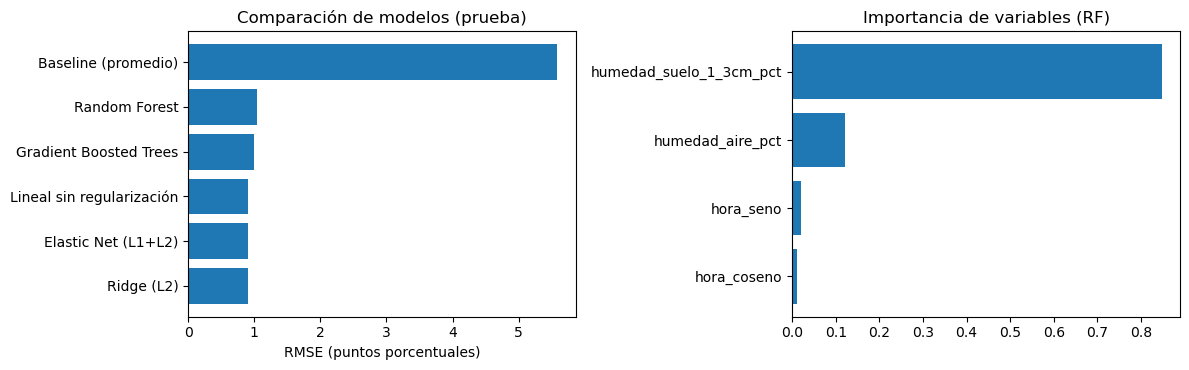

In [23]:
imp = sorted(zip(PREDICTORES, rf.featureImportances.toArray()), key=lambda x: -x[1])
print('Importancia de variables (Random Forest):')
for v, i in imp: print(f'  {v:26s} {i:.4f}')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
c2 = comp.sort_values('RMSE'); ax[0].barh(c2.Modelo, c2.RMSE); ax[0].set_xlabel('RMSE (puntos porcentuales)'); ax[0].set_title('Comparación de modelos (prueba)')
ax[1].barh([v for v,_ in imp][::-1], [i for _,i in imp][::-1]); ax[1].set_title('Importancia de variables (RF)')
plt.tight_layout(); fig.savefig(ARTIFACTS/'u1_comparacion_modelos.png', dpi=150); plt.show()

### ⚠️ Cuidado con la variable simulada
`humedad_suelo_1_3cm_pct` se **simuló a partir del objetivo** (correlación ≈ 0.99): cualquier modelo que la use parecerá casi perfecto. Es una **fuga de información por construcción** aceptable solo para practicar el flujo. La prueba honesta es la **ablación**: reentrenar **sin** esa variable y comparar.

In [24]:
pred_sin = ['humedad_aire_pct', 'hora_seno', 'hora_coseno']
df_ml2 = VectorAssembler(inputCols=pred_sin, outputCol='features').transform(df_f).select('features', 'label')
tr2, te2 = df_ml2.randomSplit([0.8, 0.2], seed=42)
abl = []
abl.append(evaluar(te2.withColumn('prediction', F.lit(float(media))), 'Baseline (promedio)'))
abl.append(evaluar(LinearRegression(featuresCol='features', labelCol='label').fit(tr2).transform(te2), 'Lineal (sin var. simulada)'))
abl.append(evaluar(RandomForestRegressor(featuresCol='features', labelCol='label', numTrees=50, maxDepth=8, seed=42).fit(tr2).transform(te2), 'Random Forest (sin var. simulada)'))
display(pd.DataFrame(abl)[['Modelo','RMSE','R2','MAE']].round(4))
print('Lectura: sin la variable derivada del objetivo, el R² cae a lo que realmente explican la humedad del aire y la hora.')

,Modelo,RMSE,R2,MAE
0,Baseline (promedio),5.4953,-0.0054,4.0775
1,Lineal (sin var. simulada),4.4843,0.3305,3.2530
2,Random Forest (sin var. simulada),4.6891,0.2680,3.2995


Lectura: sin la variable derivada del objetivo, el R² cae a lo que realmente explican la humedad del aire y la hora.


### Selección y validación de negocio
El ganador se elige **por la tabla** (menor RMSE en prueba, *y* que supere al baseline), no por el primero que se entrenó. Se valida si el error es aceptable: el RMSE se expresa en **puntos porcentuales de humedad volumétrica** (no es % relativo). Un R² moderado significa que estas variables explican *parte* de la humedad; lo honesto es documentarlo y no afirmar capacidad predictiva real sin datos de sondas.

In [25]:
solo_modelos = comp[comp.Modelo != 'Baseline (promedio)'].sort_values('RMSE')
mejor = solo_modelos.iloc[0]; base = comp[comp.Modelo == 'Baseline (promedio)'].iloc[0]
print(f'Ganador: {mejor.Modelo} | RMSE={mejor.RMSE} R2={mejor.R2} MAE={mejor.MAE}')
print(f'Mejora sobre el baseline: RMSE {base.RMSE} → {mejor.RMSE} ({(1-mejor.RMSE/base.RMSE)*100:.1f} % menos error)')
print('¿Supera al baseline?', bool(mejor.RMSE < base.RMSE))
ganador = modelos_ml[mejor.Modelo]
ganador.write().overwrite().save(str(ARTIFACTS / 'modelo_u1_humedad_suelo'))      # Fase 6 — Deployment (guardar)
print('Modelo guardado en', ARTIFACTS / 'modelo_u1_humedad_suelo')

Ganador: Ridge (L2) | RMSE=0.9001 R2=0.974 MAE=0.5313
Mejora sobre el baseline: RMSE 5.5868 → 0.9001 (83.9 % menos error)
¿Supera al baseline? True
Modelo guardado en /home/jovyan/work/U1_Batch_Humedad/artifacts/modelo_u1_humedad_suelo


### Reflexión S4
- Resolver duplicados **antes** del `join` evita multiplicar filas sin error visible.
- `VectorAssembler` es obligatorio: MLlib exige **una sola columna vectorial** `features`.
- Ninguna métrica sola basta: RMSE penaliza errores grandes, MAE no, R² es una proporción; el baseline da contexto.
- Aquí la división es **aleatoria** porque la pregunta es *«¿qué explica la humedad ahora?»*. Para *«¿cuánta humedad habrá en 3 h?»* el orden es el dato y la división debe ser **cronológica** → Unidad 2.

---
# SECCIÓN 5 · S5 — Evaluación de la Unidad I: pipeline batch completo
Resumen verificable de **todo** el pipeline batch construido (arquitectura → PySpark → calidad → Parquet particionado → ML) y su evidencia.

In [26]:
resumen_u1 = {
  'ejecutado_utc': datetime.now(timezone.utc).isoformat(),
  'arquitectura': 'Lambda (batch + speed + serving)',
  'filas_bronze_suelo': int(tot_suelo),
  'filas_silver_gold': int(n_silver),
  'filas_descartadas_calidad': int(tot_suelo - n_silver),
  'errores_999_detectados': int(n_err),
  'duplicados_aire_resueltos': int(df_aire.count() - df_aire_u.count()),
  'particiones_gold': sorted(p for p in os.listdir(gold_path) if p.startswith('anio_mes')),
  'modelo_ganador': str(mejor.Modelo),
  'rmse_prueba_pp': float(mejor.RMSE), 'r2_prueba': float(mejor.R2), 'mae_prueba_pp': float(mejor.MAE),
  'rmse_baseline_promedio_pp': float(base.RMSE),
}
(ARTIFACTS / 'resumen_u1.json').write_text(json.dumps(resumen_u1, indent=2, ensure_ascii=False), encoding='utf-8')
display(pd.Series(resumen_u1).to_frame('valor'))

,valor
ejecutado_utc,2026-11-20T05:48:34.416205+00:00
arquitectura,Lambda (batch + speed + serving)
filas_bronze_suelo,1439
filas_silver_gold,1392
filas_descartadas_calidad,47
errores_999_detectados,25
duplicados_aire_resueltos,30
particiones_gold,"[anio_mes=2026-09, anio_mes=2026-10, anio_mes=..."
modelo_ganador,Ridge (L2)
rmse_prueba_pp,0.9001


### Lista de verificación de la rúbrica U1 (marca con evidencia)
| Criterio | Evidencia en este cuaderno | ✔ |
|---|---|---|
| S1 · Clasificación batch/streaming y regla de decisión | Secciones 1.3–1.4 | ☐ |
| S1 · Tecnologías, diagrama y ficha completa | 1.4–1.5 | ☐ |
| S2 · Extracción y esquema explícito | 2.2 | ☐ |
| S2 · Transformaciones, funciones y *lazy evaluation* + `explain()` | 2.3–2.5 | ☐ |
| S2 · Agrupaciones, ventanas y RDD | 2.6–2.8 | ☐ |
| S3 · Esquema, nulos, códigos de error y duplicados | 3.1–3.4 | ☐ |
| S3 · Parquet particionado leído de vuelta y `PartitionFilters` | 3.6 | ☐ |
| S4 · Vector, split, modelo base, regularización, 2º/3er algoritmo, importancia | Sección 4 | ☐ |
| S4 · Comparación final, validación de negocio y modelo guardado | Sección 4 (selección) | ☐ |

**Evidencias a capturar (con reloj del sistema y usuario visibles):** Docker Desktop con contenedores, Jupyter con Spark UI, `explain(True)`, conteos de calidad, carpetas `anio_mes=…`, tabla comparativa y `resumen_u1.json`.

### Preguntas de defensa (respuestas cortas)
1. **¿Por qué Lambda?** Porque hay histórico (entrenar) y tiempo real (inferir); el modelo cruza del batch al speed layer.
2. **¿Nulo vs. −999?** El nulo es ausencia; −999 es un valor válido para Spark que significa error de sensor; `isNull()` no lo detecta.
3. **¿`dropDuplicates` vs. `Window+row_number`?** El primero elige una fila cualquiera; el segundo permite elegir cuál conservar (aquí, la de menos nulos).
4. **¿`PartitionFilters`?** Descarta carpetas sin abrir archivos; es más barato que `PushedFilters`.
5. **¿Por qué comparar varios modelos?** Un solo modelo sin comparar es riesgo (caso Zillow); las métricas se contrastan con un baseline.

> **Siguiente paso:** abre `Sensorhumedad/U2_AgroSmart_S06_S12_Humedad_Tiempo_Real.ipynb`. La Unidad 2 lleva esta misma idea a tiempo real con Kafka, Spark Structured Streaming, PostgreSQL y Grafana, y predice **+1, +2 y +3 horas**.